# BTC/USDT 30-min — Momentum Strategy (k-bar return)

Rule-based benchmark to compare against the LightGBM / LSTM models in this folder.

**Concept**: prices that move strongly in one direction tend to keep going in the short term.

$$R_t = \frac{P_t - P_{t-k}}{P_{t-k}}, \qquad k = \text{lookback in bars}$$

Example from the brief: WTI 78.50 → 78.95 in 15 min gives R = 0.57% > 0.5% → **long**;
R < −0.5% → **short**.

On 30-min BTC bars the shortest lookback is **k = 1 bar (30 min)**. After an entry signal the
position is held for **H bars** using `hold_signals` from the trade-tracker (a new signal in the
same direction resets the clock, an opposite one flips).

| name | rule |
|---|---|
| `slide rule` | k = 1 bar, threshold 0.5%, hold 1 bar (re-evaluated every bar) |
| `best (val)` | k, threshold, H chosen by validation Sharpe |
| `vol-scaled` | threshold = c × rolling σ of k-bar returns instead of a fixed 0.5% |
| `long-only` | same rules but **never short**: buy when R > threshold, sell back to cash after H bars |

**No look-ahead**: R_t uses the close of bar *t*; the order is filled at the **open of bar t+1**.
Backtest, costs and metrics come from `AlgoGoneCrazy-dev-trade-tracker/src`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)


def find_repo_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the notebook folder until the folder holding all AlgoGoneCrazy-dev-* repos."""
    for p in [start, *start.parents]:
        if (p / "AlgoGoneCrazy-dev-trade-tracker").is_dir():
            return p
    raise FileNotFoundError("Could not find AlgoGoneCrazy-dev-trade-tracker above " + str(start))


REPO_ROOT = find_repo_root()
TRACKER_DIR = REPO_ROOT / "AlgoGoneCrazy-dev-trade-tracker"   # backtest engine + metrics
MODEL_DIR = REPO_ROOT / "AlgoGoneCrazy-dev-model" / "model"
RESULTS_DIR = MODEL_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# import the shared backtest / metrics code from the trade-tracker repo
if str(TRACKER_DIR) not in sys.path:
    sys.path.insert(0, str(TRACKER_DIR))
from src.backtest import run_backtest, buy_and_hold
from src.strategy import hold_signals
from src.metrics import compute_metrics, drawdown_series

print("repo root   :", REPO_ROOT)
print("backtest src:", TRACKER_DIR / "src")

repo root   : C:/Users/user/projects/Githubrepo
backtest src: C:/Users/user/projects/Githubrepo/AlgoGoneCrazy-dev-trade-tracker/src


## 1. Settings

In [2]:
# --- transaction costs (BTC on Binance, see AlgoGoneCrazy-dev-data/config/cost_assumptions.json)
FEE_BPS = 10.0          # 0.10% standard spot fee per order, no BNB discount
SLIPPAGE_BPS = 2.0      # half-spread + impact per order (same as trade-tracker config.py)
INITIAL_CASH = 100_000.0
ALLOW_SHORT = True

# --- chronological split, same fractions as the ML notebooks (70 / 15 / 15)
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

BT_KW = dict(initial_cash=INITIAL_CASH, fee_bps=FEE_BPS, slippage_bps=SLIPPAGE_BPS)

# --- slide-rule parameters
SLIDE_K = 1             # 1 bar = 30 minutes (closest to the brief's 15 min on 30-min data)
SLIDE_THRESHOLD = 0.005 # 0.5%
SLIDE_HOLD = 1

# --- search grid (chosen on VALIDATION Sharpe)
GRID_K = [1, 2, 4, 8]                        # 30m, 1h, 2h, 4h
GRID_THRESHOLD = [0.005, 0.01, 0.015, 0.02]
GRID_HOLD = [1, 4, 12]                       # 30m, 2h, 6h

# --- volatility-scaled variant
VOL_WINDOW = 48 * 7     # one week of bars for sigma of k-bar returns
VOL_MULT = 2.0

SIDES = {"long/short": True, "long-only": False}   # grid is searched for both

TAG = "btc_momentum"

## 2. Load 30-min BTC bars

In [3]:
# First file found is used: DATA_PATH if set, then the newest BTCUSDT snapshot in the team's
# "Tsai Yi Kai - FE5209_Group_Project" OneDrive folder, then model/data/ (where the ML notebooks
# read from), then the dev-data canonical multi-asset file (filtered to BTC).
DATA_PATH = None   # set a full path here to override the search below


def shared_drive_btc_files():
    """Team OneDrive folder: .../FE5209_Group_Project/data/<yymmdd>/staging/binance_spot/BTCUSDT/.
    Newest dated snapshot first."""
    hits = []
    for base in (Path.home() / "National University of Singapore", REPO_ROOT.parent, REPO_ROOT):
        if base.is_dir():
            hits += base.glob("*FE5209_Group_Project/data/*/staging/binance_spot/BTCUSDT/"
                              "market_bars_30m_with_backfill.csv")
    return sorted(set(hits), key=lambda p: p.parts[-5], reverse=True)


DATA_CANDIDATES = ([Path(DATA_PATH)] if DATA_PATH else []) + shared_drive_btc_files() + [
    MODEL_DIR / "data" / "market_bars_30m_with_backfill.csv",
    REPO_ROOT / "AlgoGoneCrazy-dev-model" / "data" / "market_bars_30m_with_backfill.csv",
    TRACKER_DIR / "data" / "market_bars_30m_with_backfill.csv",
    REPO_ROOT / "AlgoGoneCrazy-dev-data" / "data" / "canonical" / "market_bars_30m.csv",
]
SYMBOL = "BTCUSDT"


def load_btc_bars(candidates=DATA_CANDIDATES, symbol=SYMBOL) -> pd.DataFrame:
    path = next((p for p in candidates if p.exists()), None)
    if path is None:
        raise FileNotFoundError("No 30-min bar CSV found. Put it in one of:\n" +
                                "\n".join(str(p) for p in candidates))
    raw = pd.read_csv(path)
    raw.columns = [c.lower() for c in raw.columns]
    for col in ("source_symbol", "instrument_id", "symbol"):       # multi-asset file -> BTC only
        if col in raw.columns and raw[col].nunique() > 1:
            raw = raw[raw[col].astype(str).str.upper().str.contains("BTC")]
            break
    # UTC, stored tz-naive: trade-tracker's drawdown_episodes() fails on tz-aware
    # timestamps when the last drawdown is still open (NaT + tz-aware -> object dtype)
    raw.index = pd.DatetimeIndex(pd.to_datetime(raw.pop("bar_open_time_utc"), utc=True)).tz_convert(None)
    raw = raw.sort_index()
    raw = raw[~raw.index.duplicated(keep="last")]
    print("loaded:", path)
    return raw[["open", "high", "low", "close", "volume"]].astype(float)


bars = load_btc_bars()
print(bars.shape, bars.index.min(), "->", bars.index.max())
bars.tail()

loaded: C:/Users/user/National University of Singapore/Tsai Yi Kai - FE5209_Group_Project/data/260918/staging/binance_spot/BTCUSDT/market_bars_30m_with_backfill.csv
(52608, 5) 2023-09-17 00:00:00 -> 2026-09-16 23:30:00


,open,high,low,close,volume
bar_open_time_utc,,,,,
2026-09-16 21:30:00,76074.56,76099.98,75933.11,75976.00,126.43911
2026-09-16 22:00:00,75976.01,75986.01,75667.24,75758.21,306.49196
2026-09-16 22:30:00,75758.21,75820.01,75632.70,75675.88,219.03523
2026-09-16 23:00:00,75675.88,76140.62,75643.61,76076.49,236.74200
2026-09-16 23:30:00,76076.49,76276.02,76063.77,76206.01,247.73664


In [4]:
n = len(bars)
train_end, val_end = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
periods = {
    "train": (bars.index[0], bars.index[train_end - 1]),
    "val": (bars.index[train_end], bars.index[val_end - 1]),
    "test": (bars.index[val_end], bars.index[-1]),
}
for k, (a, b) in periods.items():
    print(f"{k:5s}: {a} -> {b}")


def sl(obj, period):
    """Slice a Series/DataFrame to one period (indicators are computed on the full history
    first, so each period starts with warmed-up signals and no look-ahead)."""
    a, b = periods[period]
    return obj.loc[a:b]

train: 2023-09-17 00:00:00 -> 2025-10-23 04:00:00
val  : 2025-10-23 04:30:00 -> 2026-04-05 13:30:00
test : 2026-04-05 14:00:00 -> 2026-09-16 23:30:00


## 3. Momentum signal and position rules

In [5]:
def kbar_return(close: pd.Series, k: int) -> pd.Series:
    return close / close.shift(k) - 1


def momentum_signal(R: pd.Series, threshold, allow_short: bool = ALLOW_SHORT) -> pd.Series:
    """+1 if R > threshold, -1 if R < -threshold, else 0. `threshold` may be a Series."""
    sig = pd.Series(0, index=R.index, dtype=int)
    sig[R > threshold] = 1
    if allow_short:
        sig[R < -threshold] = -1
    return sig


def momentum_positions(close: pd.Series, k: int, threshold, hold: int,
                       allow_short: bool = ALLOW_SHORT) -> pd.Series:
    """Signal at the close of bar t -> entry at the open of bar t+1, held `hold` bars."""
    sig = momentum_signal(kbar_return(close, k), threshold, allow_short)
    return hold_signals(sig.shift(1).fillna(0).astype(int), horizon=hold)


close = bars["close"]
R1 = kbar_return(close, SLIDE_K)

# worked example from the brief
print("example R =", round((78.95 - 78.50) / 78.50, 4), "-> long" if (78.95 - 78.50) / 78.50 > 0.005 else "")
print("share of bars with |R| > 0.5% (k=1):", round((R1.abs() > SLIDE_THRESHOLD).mean(), 4))
R1.describe()

example R = 0.0057 -> long
share of bars with |R| > 0.5% (k=1): 0.1022


count    52607.000000
mean         0.000026
std          0.003573
min         -0.051329
25%         -0.001474
50%          0.000041
75%          0.001527
max          0.051726
Name: close, dtype: float64

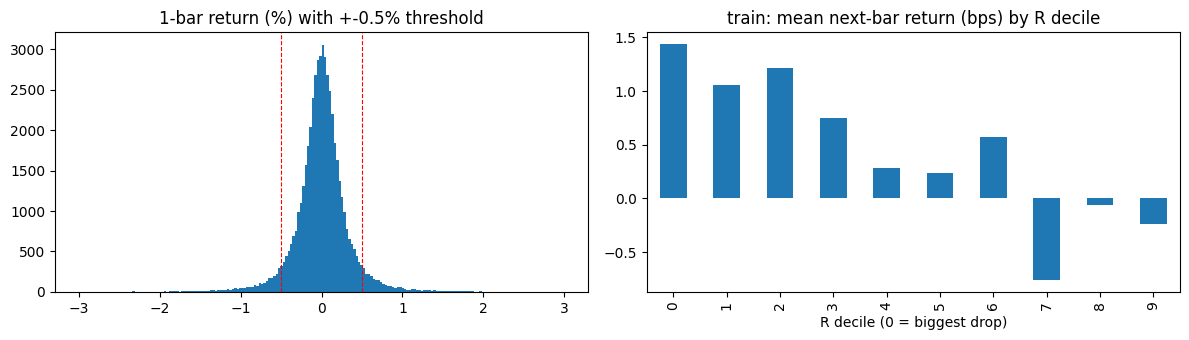

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(R1.dropna() * 100, bins=200, range=(-3, 3))
for t in (SLIDE_THRESHOLD, -SLIDE_THRESHOLD):
    axes[0].axvline(t * 100, color="r", ls="--", lw=0.8)
axes[0].set_title(f"{SLIDE_K}-bar return (%) with +-{SLIDE_THRESHOLD:.1%} threshold")

# does a big move predict the next bar? (the momentum hypothesis, train period only)
fwd = close.shift(-1) / close - 1
d = pd.DataFrame({"R": R1, "fwd": fwd}).dropna()
d = sl(d, "train")
d["bucket"] = pd.qcut(d["R"], 10, labels=False)
(d.groupby("bucket")["fwd"].mean() * 1e4).plot.bar(ax=axes[1])
axes[1].set_title("train: mean next-bar return (bps) by R decile")
axes[1].set_xlabel("R decile (0 = biggest drop)")
plt.tight_layout()
plt.show()

## 4. Backtest helpers (shared trade-tracker engine)

In [7]:
def backtest(pos: pd.Series, period: str):
    """Run the shared trade-tracker engine on one period (starts flat, closes out at the end)."""
    return run_backtest(sl(pos, period), sl(bars, period), asset="BTC", **BT_KW)


def metrics(res) -> pd.Series:
    return compute_metrics(res.equity, res.trades, res.positions, res.fills)


# the rows people actually look at first
KEY_ROWS = ["Total Return", "Annual Return", "Annual Volatility", "Sharpe Ratio", "Sortino Ratio",
            "Max Drawdown", "Calmar Ratio", "Number of Trades", "Win Rate",
            "Average Holding Period (hours)", "Profit Factor", "Exposure (time in market)",
            "Annual Return (before costs)", "Annual Cost Drag", "Total Transaction Cost"]

## 5. Parameter search on the validation period

Each (k, threshold, hold) combination is backtested on **train** and **validation** with full
costs; the best validation Sharpe is kept (train Sharpe shown as a stability check).

In [8]:
rows = []
for side, short_ok in SIDES.items():
  for k in GRID_K:
    for th in GRID_THRESHOLD:
        for h in GRID_HOLD:
            pos = momentum_positions(close, k, th, h, allow_short=short_ok)
            row = {"side": side, "k": k, "threshold": th, "hold": h}
            for p in ("train", "val"):
                m = metrics(backtest(pos, p))
                row[f"{p}_sharpe"] = m["Sharpe Ratio"]
                row[f"{p}_ann_ret"] = m["Annual Return"]
                row[f"{p}_mdd"] = m["Max Drawdown"]
                row[f"{p}_trades"] = m["Number of Trades"]
            rows.append(row)
grid = pd.DataFrame(rows).sort_values("val_sharpe", ascending=False).reset_index(drop=True)
grid.head(10).round(3)

,side,k,threshold,hold,train_sharpe,train_ann_ret,train_mdd,train_trades,val_sharpe,val_ann_ret,val_mdd,val_trades
0,long-only,1,0.020,4,-0.488,-0.043,-0.125,42.0,0.774,0.065,-0.040,9.0
1,long-only,8,0.020,12,0.093,-0.007,-0.300,236.0,0.597,0.103,-0.107,49.0
2,long-only,1,0.015,12,0.322,0.042,-0.152,108.0,0.342,0.040,-0.102,24.0
3,long/short,1,0.020,12,-0.844,-0.145,-0.333,85.0,0.140,0.010,-0.089,19.0
4,long-only,1,0.020,12,-0.657,-0.079,-0.176,41.0,0.073,0.002,-0.054,9.0
5,long/short,1,0.020,4,-0.956,-0.128,-0.257,88.0,-0.070,-0.016,-0.048,21.0
6,long-only,1,0.015,4,-0.112,-0.022,-0.169,118.0,-0.075,-0.013,-0.085,25.0
7,long-only,1,0.020,1,-1.240,-0.072,-0.153,46.0,-0.206,-0.011,-0.023,10.0
8,long/short,1,0.020,1,-1.673,-0.163,-0.318,93.0,-0.345,-0.033,-0.053,22.0
9,long-only,2,0.015,12,0.188,0.017,-0.257,207.0,-0.364,-0.083,-0.181,36.0


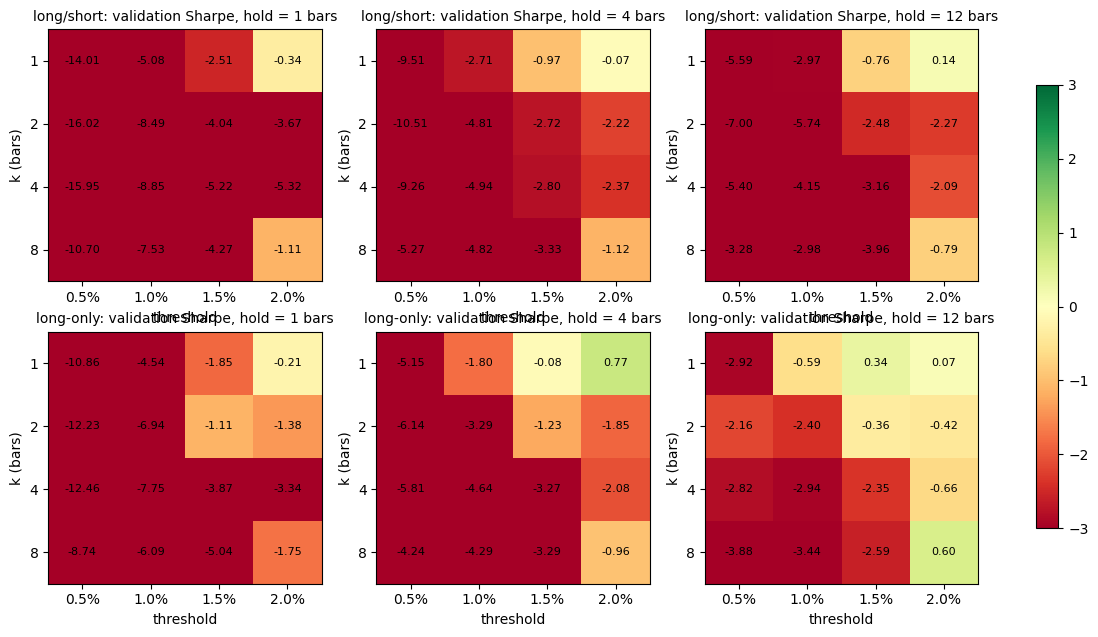

long/short chosen on validation: k=1, threshold=2.00%, hold=12
long-only  chosen on validation: k=1, threshold=2.00%, hold=4


In [9]:
fig, axes = plt.subplots(len(SIDES), len(GRID_HOLD), figsize=(5 * len(GRID_HOLD), 3.6 * len(SIDES)),
                         squeeze=False)
for ax, (side, h) in zip(axes.ravel(), [(sd_, h_) for sd_ in SIDES for h_ in GRID_HOLD]):
    hm = grid[(grid.side == side) & (grid.hold == h)].pivot(index="k", columns="threshold",
                                                              values="val_sharpe")
    im = ax.imshow(hm.values, cmap="RdYlGn", vmin=-3, vmax=3, aspect="auto")
    ax.set_xticks(range(hm.shape[1]), [f"{c:.1%}" for c in hm.columns])
    ax.set_yticks(range(hm.shape[0]), hm.index)
    for i in range(hm.shape[0]):
        for j in range(hm.shape[1]):
            v = hm.values[i, j]
            ax.text(j, i, "n/a" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=8)
    ax.set_xlabel("threshold")
    ax.set_ylabel("k (bars)")
    ax.set_title(f"{side}: validation Sharpe, hold = {h} bars", fontsize=10)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.8)
plt.show()

g = grid.dropna(subset=["val_sharpe"])
best = g[g.side == "long/short"].iloc[0]
BEST_K, BEST_TH, BEST_H = int(best.k), float(best.threshold), int(best.hold)
best_lo = g[g.side == "long-only"].iloc[0]
LO_K, LO_TH, LO_H = int(best_lo.k), float(best_lo.threshold), int(best_lo.hold)
print(f"long/short chosen on validation: k={BEST_K}, threshold={BEST_TH:.2%}, hold={BEST_H}")
print(f"long-only  chosen on validation: k={LO_K}, threshold={LO_TH:.2%}, hold={LO_H}")

## 6. Final positions for every variant

In [10]:
# volatility-scaled threshold: sigma of k-bar returns over the past week, known at bar t
Rb = kbar_return(close, BEST_K)
vol_th = VOL_MULT * Rb.rolling(VOL_WINDOW).std()

BEST_NAME = f"best val (k={BEST_K}, th={BEST_TH:.1%}, H={BEST_H})"
strategies = {
    f"slide rule (k={SLIDE_K}, th={SLIDE_THRESHOLD:.1%}, H={SLIDE_HOLD})":
        momentum_positions(close, SLIDE_K, SLIDE_THRESHOLD, SLIDE_HOLD),
    BEST_NAME:
        momentum_positions(close, BEST_K, BEST_TH, BEST_H),
    f"vol-scaled (k={BEST_K}, {VOL_MULT} sd, H={BEST_H})":
        momentum_positions(close, BEST_K, vol_th, BEST_H),
    # long-only: buy after a strong up-move, sell back to cash after H bars - never short
    f"LONG-ONLY slide rule (k={SLIDE_K}, th={SLIDE_THRESHOLD:.1%}, H={SLIDE_HOLD})":
        momentum_positions(close, SLIDE_K, SLIDE_THRESHOLD, SLIDE_HOLD, allow_short=False),
    f"LONG-ONLY best (k={LO_K}, th={LO_TH:.1%}, H={LO_H})":
        momentum_positions(close, LO_K, LO_TH, LO_H, allow_short=False),
    f"LONG-ONLY vol-scaled (k={LO_K}, {VOL_MULT} sd, H={LO_H})":
        momentum_positions(close, LO_K, VOL_MULT * kbar_return(close, LO_K).rolling(VOL_WINDOW).std(),
                           LO_H, allow_short=False),
}
pd.DataFrame({k: v.value_counts(normalize=True) for k, v in strategies.items()}).round(3)

,"slide rule (k=1, th=0.5%, H=1)","best val (k=1, th=2.0%, H=12)","vol-scaled (k=1, 2.0 sd, H=12)","LONG-ONLY slide rule (k=1, th=0.5%, H=1)","LONG-ONLY best (k=1, th=2.0%, H=4)","LONG-ONLY vol-scaled (k=1, 2.0 sd, H=4)"
position,,,,,,
-1,0.050,0.012,0.179,NaN,NaN,NaN
0,0.898,0.976,0.635,0.948,0.995,0.906
1,0.052,0.012,0.186,0.052,0.005,0.094


## 7. Performance matrix — test period (out of sample)

In [11]:
test_results = {name: backtest(pos, "test") for name, pos in strategies.items()}
test_results["Buy & Hold"] = buy_and_hold(sl(bars, "test"), asset="BTC", **BT_KW)

table = pd.DataFrame({name: metrics(res) for name, res in test_results.items()})
table.loc[KEY_ROWS].style.format("{:,.4f}")

,"slide rule (k=1, th=0.5%, H=1)","best val (k=1, th=2.0%, H=12)","vol-scaled (k=1, 2.0 sd, H=12)","LONG-ONLY slide rule (k=1, th=0.5%, H=1)","LONG-ONLY best (k=1, th=2.0%, H=4)","LONG-ONLY vol-scaled (k=1, 2.0 sd, H=4)",Buy & Hold
Total Return,-0.7085,-0.0649,-0.5073,-0.4056,-0.0409,-0.2415,0.1378
Annual Return,-0.9352,-0.1385,-0.7923,-0.6850,-0.0886,-0.4586,0.3318
Annual Volatility,0.1889,0.0793,0.2875,0.1428,0.0459,0.1853,0.3887
Sharpe Ratio,-14.3935,-1.8405,-5.3228,-8.0176,-1.9988,-3.2192,0.9317
Sortino Ratio,-18.0174,-2.3055,-7.3676,-11.4223,-2.2088,-4.9045,1.3367
Max Drawdown,-0.7166,-0.0856,-0.5434,-0.4219,-0.0483,-0.2828,-0.2953
Calmar Ratio,-1.3051,-1.6169,-1.4580,-1.6233,-1.8350,-1.6219,1.1237
Number of Trades,470.0000,8.0000,283.0000,246.0000,5.0000,159.0000,1.0000
Win Rate,0.2128,0.2500,0.3357,0.2358,0.4000,0.3145,1.0000
Average Holding Period (hours),0.5670,6.0000,5.0901,0.5772,2.0000,2.2987,"3,945.5000"


In [12]:
# full matrix, all metrics from src/metrics.py (incl. transaction-cost section)
table.style.format("{:,.4f}")

,"slide rule (k=1, th=0.5%, H=1)","best val (k=1, th=2.0%, H=12)","vol-scaled (k=1, 2.0 sd, H=12)","LONG-ONLY slide rule (k=1, th=0.5%, H=1)","LONG-ONLY best (k=1, th=2.0%, H=4)","LONG-ONLY vol-scaled (k=1, 2.0 sd, H=4)",Buy & Hold
Total Return,-0.7085,-0.0649,-0.5073,-0.4056,-0.0409,-0.2415,0.1378
Annual Return,-0.9352,-0.1385,-0.7923,-0.6850,-0.0886,-0.4586,0.3318
Annual Volatility,0.1889,0.0793,0.2875,0.1428,0.0459,0.1853,0.3887
Sharpe Ratio,-14.3935,-1.8405,-5.3228,-8.0176,-1.9988,-3.2192,0.9317
Sortino Ratio,-18.0174,-2.3055,-7.3676,-11.4223,-2.2088,-4.9045,1.3367
Max Drawdown,-0.7166,-0.0856,-0.5434,-0.4219,-0.0483,-0.2828,-0.2953
Calmar Ratio,-1.3051,-1.6169,-1.4580,-1.6233,-1.8350,-1.6219,1.1237
Drawdown Count (>= 1%),2.0000,2.0000,4.0000,1.0000,2.0000,3.0000,11.0000
Longest Drawdown (days),162.0000,103.1875,156.0000,162.0000,28.2917,156.0000,133.5000
Number of Trades,470.0000,8.0000,283.0000,246.0000,5.0000,159.0000,1.0000


### Same strategies on every period (stability check)

In [13]:
full = {}
for name, pos in strategies.items():
    for p in ("train", "val", "test"):
        m = metrics(backtest(pos, p))
        full[(name, p)] = m[["Annual Return", "Sharpe Ratio", "Max Drawdown", "Number of Trades", "Win Rate"]]
full_table = pd.DataFrame(full).T
full_table.round(3)

Annual Return  Sharpe Ratio  Max Drawdown  Number of Trades  Win Rate
slide rule (k=1, th=0.5%, H=1)           train         -0.981       -14.239        -1.000            3308.0     0.234
                                         val           -0.982       -14.014        -0.838             812.0     0.255
                                         test          -0.935       -14.393        -0.717             470.0     0.213
best val (k=1, th=2.0%, H=12)            train         -0.145        -0.844        -0.333              85.0     0.424
                                         val            0.010         0.140        -0.089              19.0     0.474
                                         test          -0.138        -1.841        -0.086               8.0     0.250
vol-scaled (k=1, 2.0 sd, H=12)           train         -0.676        -2.846        -0.914            1282.0     0.369
                                         val           -0.732        -3.230        -0.463             281.0     0.388
                                         test          -0.792        -5.323        -0.543             283.0     0.336
LONG-ONLY slide rule (k=1, th=0.5%, H=1) train         -0.849       -10.167        -0.981            1709.0     0.240
                                         val           -0.857       -10.858        -0.584             394.0     0.256
                                         test          -0.685        -8.018        -0.422             246.0     0.236
LONG-ONLY best (k=1, th=2.0%, H=4)       train         -0.043        -0.488        -0.125              42.0     0.500
                                         val            0.065         0.774        -0.040               9.0     0.556
                                         test          -0.089        -1.999        -0.048               5.0     0.400
LONG-ONLY vol-scaled (k=1, 2.0 sd, H=4)  train         -0.495        -2.955        -0.775             743.0     0.384
                                         val           -0.566        -4.083        -0.320             146.0     0.336
                                         test          -0.459        -3.219        -0.283             159.0     0.314

## 8. Equity, drawdown and trades (test)

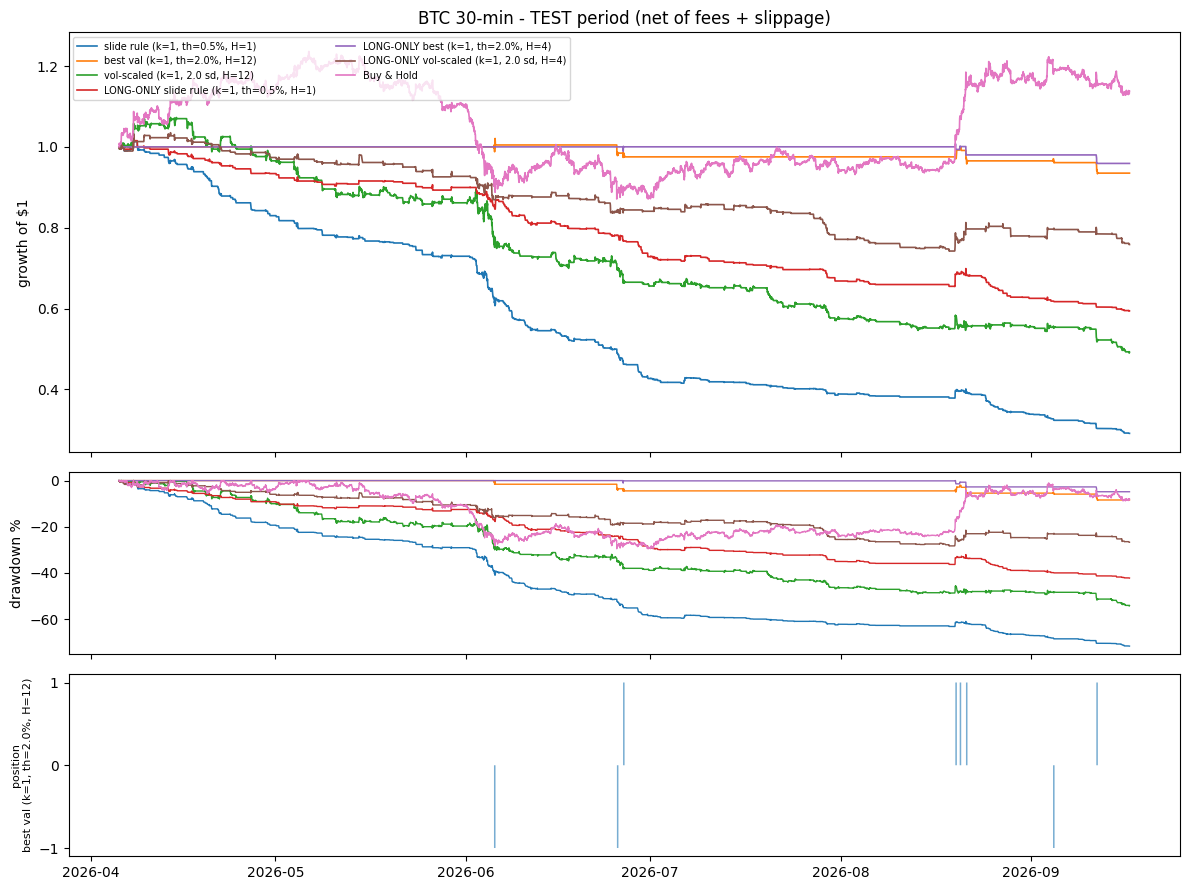

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1.3, 1.3]})
for name, res in test_results.items():
    axes[0].plot(res.equity.index, res.equity / res.equity.iloc[0], label=name, lw=1.2)
    axes[1].plot(res.equity.index, drawdown_series(res.equity) * 100, label=name, lw=1)
axes[0].set_ylabel("growth of $1")
axes[0].set_title("BTC 30-min - TEST period (net of fees + slippage)")
axes[0].legend(loc="upper left", fontsize=7, ncol=2)
axes[1].set_ylabel("drawdown %")
best_pos = test_results[BEST_NAME].positions["BTC"]
axes[2].fill_between(best_pos.index, best_pos, step="post", alpha=0.6)
axes[2].set_ylabel("position\n" + BEST_NAME, fontsize=8)
axes[2].set_yticks([-1, 0, 1])
plt.tight_layout()
fig.savefig(RESULTS_DIR / f"{TAG}_equity_drawdown.png", dpi=130)
plt.show()

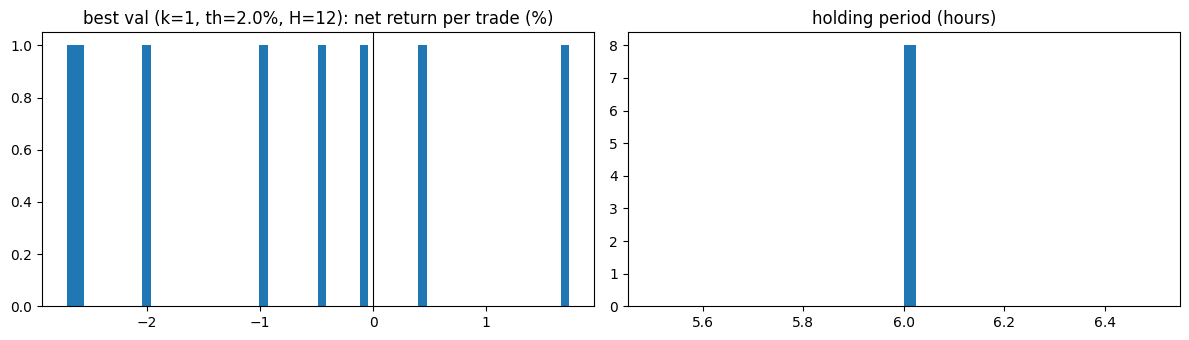

net_pnl                          return_pct                    
        count        mean          sum      count      mean       sum
side                                                                 
long        5 -903.615158 -4518.075790          5 -0.009236 -0.046180
short       3 -658.236495 -1974.709484          3 -0.006604 -0.019811

In [15]:
tr = test_results[BEST_NAME].trades
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(tr["return_pct"] * 100, bins=60)
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_title(f"{BEST_NAME}: net return per trade (%)")
axes[1].hist(tr["holding_period"].dt.total_seconds() / 3600, bins=40)
axes[1].set_title("holding period (hours)")
plt.tight_layout()
plt.show()
tr.groupby("side")[["net_pnl", "return_pct"]].agg(["count", "mean", "sum"])

## 9. Save outputs

In [16]:
table.to_csv(RESULTS_DIR / f"{TAG}_metrics_test.csv")
grid.to_csv(RESULTS_DIR / f"{TAG}_param_grid.csv", index=False)
test_results[BEST_NAME].trades.to_csv(RESULTS_DIR / f"{TAG}_trades_test.csv", index=False)
full_table.to_csv(RESULTS_DIR / f"{TAG}_metrics_by_period.csv")
print("saved to", RESULTS_DIR)
for f in sorted(RESULTS_DIR.glob(f"{TAG}_*")):
    print("  ", f.name)

saved to C:/Users/user/projects/Githubrepo/AlgoGoneCrazy-dev-model/model/results
   btc_momentum_equity_drawdown.png
   btc_momentum_metrics_by_period.csv
   btc_momentum_metrics_test.csv
   btc_momentum_param_grid.csv
   btc_momentum_trades_test.csv


## Notes

- Costs: 10 bps fee + 2 bps slippage **per order** (~24 bps round trip). With H = 1 the slide rule can
  trade almost every time |R| > 0.5%, so compare *Annual Return (before costs)* with *Annual Return*.
- A fixed 0.5% threshold means very different things in calm and volatile regimes; the vol-scaled
  variant keeps the trade frequency more stable across the sample.
- The 30-min bar is the finest resolution in our pipeline, so the brief's 15-minute lookback
  is approximated by k = 1 bar.